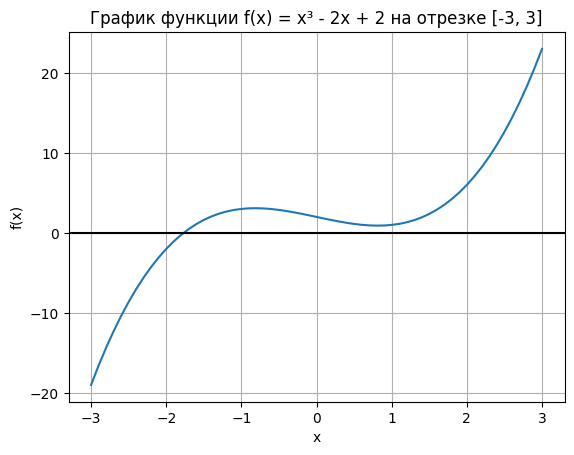

In [1]:
#Задача 1. Пункт 1

import matplotlib.pyplot as plt

f = lambda x: x**3 - 2*x + 2

x_vals = [i / 10 for i in range(-30, 31)]
y_vals = [f(x) for x in x_vals]

plt.plot(x_vals, y_vals)
plt.axhline(0, color="black")
plt.grid(True)
plt.title("График функции f(x) = x³ - 2x + 2 на отрезке [-3, 3]")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.show()


In [7]:
#Пункт 2-3

root_n0, jn0, status0 = newton(f, df, x0=0.0, eps=1e-12)
print("Ньютон x0 = 0 (первые 8 шагов):")
for row in jn0[:8]:
    print(row["iter"], round(row["x"], 6), round(row["f(x)"], 6), round(row["f'(x)"], 6), round(row["step"], 6))
print("Статус:", status0, "итераций:", len(jn0))

root_n2, jn2, status2 = newton(f, df, x0=-2.0, eps=1e-12)
print("\nНьютон x0 = -2:")
for row in jn2:
    print(row["iter"], round(row["x"], 10), f"{row['f(x)']:.2e}", round(row["f'(x)"], 6), f"{row['step']:.2e}")
print(f"Корень = {root_n2:.12f}, итераций: {len(jn2)}")


Ньютон x0 = 0 (первые 8 шагов):
1 0.0 2.0 -2.0 1.0
2 1.0 1.0 1.0 1.0
3 0.0 2.0 -2.0 1.0
4 1.0 1.0 1.0 1.0
5 0.0 2.0 -2.0 1.0
6 1.0 1.0 1.0 1.0
7 0.0 2.0 -2.0 1.0
8 1.0 1.0 1.0 1.0
Статус: max_iter итераций: 100

Ньютон x0 = -2:
1 -2.0 -2.00e+00 10.0 2.00e-01
2 -1.8 -2.32e-01 7.72 3.01e-02
3 -1.7699481865 -4.85e-03 7.39815 6.56e-04
4 -1.7692926629 -2.28e-06 7.39119 3.09e-07
5 -1.7692923542 -5.05e-13 7.391186 6.84e-14
Корень = -1.769292354239, итераций: 5


In [8]:
#Пункт 4

root_s, js, status_s = secant(f, x0=-2.0, x1=-1.0, eps=1e-12)
print("Секущие x0 = -2, x1 = -1:")
for row in js:
    print(row["iter"], round(row["x_prev"], 10), round(row["x_curr"], 10), f"{row['f_curr']:.2e}", f"{row['step']:.2e}")
print(f"Корень = {root_s:.12f}, итераций: {len(js)}")


Секущие x0 = -2, x1 = -1:
1 -2.0 -1.0 3.00e+00 6.00e-01
2 -1.0 -1.6 1.10e+00 3.49e-01
3 -1.6 -1.9493670886 -1.51e+00 2.02e-01
4 -1.9493670886 -1.7476129346 1.58e-01 1.91e-02
5 -1.7476129346 -1.7667091237 1.91e-02 2.62e-03
6 -1.7667091237 -1.7693330951 -3.01e-04 4.08e-05
7 -1.7693330951 -1.7692922786 5.59e-07 7.57e-08
8 -1.7692922786 -1.7692923542 1.64e-11 2.21e-12
9 -1.7692923542 -1.7692923542 0.00e+00 0.00e+00
Корень = -1.769292354239, итераций: 9


In [4]:
#Пункт 5

def bisection(f, a, b, eps=1e-12, max_iter=200):
    fa, fb = f(a), f(b)
    if fa * fb > 0:
        raise ValueError("Нет смены знака")
    for k in range(1, max_iter + 1):
        c = (a + b) / 2
        fc = f(c)
        if fc == 0 or (b - a) < eps:
            return c, k
        if fa * fc < 0:
            b = c
        else:
            a = c
            fa = fc
    return c, k

root_b, n_b = bisection(f, -2.0, -1.0, eps=1e-12)
print(f"Пункт 5. Бисекция на [-2, -1]: корень = {root_b:.12f}, итераций: {n_b}")


Пункт 5. Бисекция на [-2, -1]: корень = -1.769292354239, итераций: 41


In [6]:
#Пункт 6

print(f"{'Метод':<12} | {'Старт':<18} | {'Корень':<20} | {'Итераций':>10}")
print("-" * 68)
print(f"{'Ньютон':<12} | {'x0 = 0':<18} | {'не сошёлся цикл':<20} | {len(jn0):>10}")
print(f"{'Ньютон':<12} | {'x0 = -2':<18} | {root_n2:<20.12f} | {len(jn2):>10}")
print(f"{'Секущие':<12} | {'x0 = -2, x1 = -1':<18} | {root_s:<20.12f} | {len(js):>10}")
print(f"{'Бисекция':<12} | {'[-2, -1]':<18} | {root_b:<20.12f} | {n_b:>10}")


Метод        | Старт              | Корень               |   Итераций
--------------------------------------------------------------------
Ньютон       | x0 = 0             | не сошёлся цикл      |        100
Ньютон       | x0 = -2            | -1.769292354239      |          5
Секущие      | x0 = -2, x1 = -1   | -1.769292354239      |          9
Бисекция     | [-2, -1]           | -1.769292354239      |         41
